# Collectives from point-to-point messages

Imagine several workers computing parts of a result. Before they can continue, they may
need to share those parts or add their contributions together. These recurring group
operations are called **collectives**, and every rank takes part.

Each column below is one rank. The pictures show what the ranks have before an operation
and what they get from it. Separate colored marks are separate pieces; overlapping marks
mean contributions have been combined

<img src="figures/collectives-overview.png" alt="Collectives Zoo" width="900">

Keep this zoo as a reference as you work through the puzzles. NVIDIA's
[guide to collective operations](https://docs.nvidia.com/deeplearning/nccl/user-guide/docs/usage/collectives.html)
has more examples of the same operations.

The result doesn't tell us how to arrange the exchanges. Should one rank collect
everything, or could neighbours share the work? We'll build collectives from point-to-point
messages and compare rounds, data sent, and communication load across ranks.

We'll use CPU tensors, `flock.torch` (`ft`) for tensor sends and receives, and `flock`
to launch workers. Inputs are nonempty, one-dimensional tensors of the same shape and
dtype. Keep that dtype in the result, use point-to-point operations only (including in
helpers), and complete every exchange. With one rank, the input is already the answer.


In [1]:
import flock
import flock.torch as ft  # noqa: F401
import torch

from dist_puzzles import check, show_trace
from dist_puzzles.lessons.collectives import (
    check_ring_all_gather,
    check_ring_all_reduce,
    check_ring_reduce_scatter,
    check_root_all_reduce,
    check_tree_all_gather,
)


## 1. All-reduce through rank 0

Imagine every worker has computed a contribution to a vector, and everyone needs the
total. Let rank 0 collect and add the contributions, then send the total back to
everyone else. Together, these two steps — reduce and broadcast — form an all-reduce.

Implement `reduce_broadcast_all_reduce(x)`. Every rank returns the elementwise sum
of all inputs, including rank 0's contribution. All messages must have rank 0 as
their sender or receiver.


In [2]:
async def reduce_broadcast_all_reduce(x: torch.Tensor) -> torch.Tensor:
    rank = flock.get_rank()
    world = flock.get_world_size()
    if rank == 0:
        total = x.clone()
        for peer in range(1, world):
            total = total + await ft.recv(peer)
        sends = [ft.isend(peer, total) for peer in range(1, world)]
        for send in sends:
            await send.wait()
        return total

    await ft.send(0, x)
    return await ft.recv(0)


In [3]:
values = [torch.tensor([2 * rank + 1, 2 * rank + 2]) for rank in range(8)]
expected = [torch.tensor([64, 72])] * 8
run = flock.distribute(workers=len(values), seed=0, trace=True)(reduce_broadcast_all_reduce)
results, trace = run(flock.per_rank(values))
check(results, expected)
results


[tensor([64, 72]),
 tensor([64, 72]),
 tensor([64, 72]),
 tensor([64, 72]),
 tensor([64, 72]),
 tensor([64, 72]),
 tensor([64, 72]),
 tensor([64, 72])]

In [4]:
check_root_all_reduce(reduce_broadcast_all_reduce)


All checks passed.


## What does a message cost?

Everyone now has the total, but rank 0 received every other contribution and sent
every copy back. As the vectors grow, its connections have more data to carry.
Let's put a simple cost on those exchanges.

Starting a message takes time, even if its payload is tiny. Moving its bytes takes
more time, depending on the connection's bandwidth:

$$
T \approx L + \frac{n}{B}
$$

Here $L$ is the startup latency, $n$ the message size, and $B$ the bandwidth. With
**2 µs latency** and **1 KiB/µs bandwidth**, an **8 KiB** vector takes **10 µs** to send.

Now imagine our reduce + broadcast with **four ranks**, each contributing an 8 KiB
vector. Give each rank one incoming and one outgoing channel. Each channel handles
one message at a time and stays occupied for its whole transfer; independent channels
can work simultaneously. Ignore the time spent adding vectors.
Each outlined cell below represents one message occupying a channel. The blue-gray
blocks carry the same sum, including rank 0's own contribution.

<img src="figures/reduce-broadcast-cost.png" alt="Reduce plus broadcast on four ranks: rank 0 receives three vectors during the first 30 microseconds, then sends the sum to three workers during the next 30 microseconds." width="900">

Rank 0's incoming channel carries three contributions. Only then is the sum ready
for its outgoing channel to send back to the three workers: **60 µs** altogether in
this model. The queues come from shared channels, not the order of `recv` calls.
Posting every send asynchronously would not give those channels more bandwidth.

These are chosen costs, not timings from Flock. They give us two things to look for
in another algorithm: how much traffic each rank handles, and how many exchanges
must wait for earlier results. Let's start by sharing the communication work.


## 2. Ring all-gather

To try sharing that work, start with a simpler goal: each worker holds one piece of a
vector and needs all the pieces. Instead of collecting them at a coordinator, let
neighbours pass them around. Follow one color: every rank eventually gets that piece.

![Ring all-gather: four ranks, rank 0 on the left, three clockwise exchanges](figures/ring-all-gather.png)

The forwarding work is spread across the ranks, but each piece still needs successive
exchanges to reach everyone. Both parts of our cost model will matter.

Implement `ring_all_gather(x)`. Every rank returns the input tensors concatenated in
rank order. Send only to the next rank, `(rank + 1) % world_size`, using at most
`world_size - 1` messages per rank. Each message carries one input-sized tensor.

<details>
<summary>Hint: joining tensors</summary>

`torch.cat` joins the pieces into one tensor.

</details>


In [5]:
async def ring_all_gather(x: torch.Tensor) -> torch.Tensor:
    rank = flock.get_rank()
    world = flock.get_world_size()
    left = (rank - 1) % world
    right = (rank + 1) % world

    chunks = {rank: x}
    current = chunks[rank]
    for step in range(world - 1):
        send_work = ft.isend(right, current)
        current = await ft.recv(left)
        await send_work.wait()
        src = (rank - step - 1) % world
        chunks[src] = current

    return torch.cat([chunks[src] for src in range(world)])


In [6]:
values = [torch.tensor([10, 11]), torch.tensor([20, 21]), torch.tensor([30, 31]), torch.tensor([40, 41])]
expected = [torch.tensor([10, 11, 20, 21, 30, 31, 40, 41])] * 4
run = flock.distribute(workers=len(values), seed=0, trace=True)(ring_all_gather)
results, trace = run(flock.per_rank(values))
check(results, expected)
results


[tensor([10, 11, 20, 21, 30, 31, 40, 41]),
 tensor([10, 11, 20, 21, 30, 31, 40, 41]),
 tensor([10, 11, 20, 21, 30, 31, 40, 41]),
 tensor([10, 11, 20, 21, 30, 31, 40, 41])]

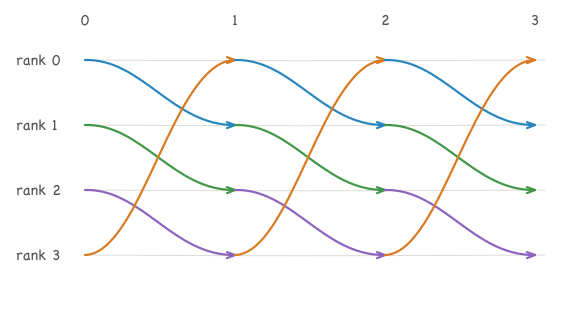

In [7]:
show_trace(trace)


In [8]:
check_ring_all_gather(ring_all_gather)


All checks passed.


## 3. Ring reduce-scatter

Now return to adding contributions. Suppose each worker contributes to a large vector,
but its next computation only needs one part of the total. There is no need to send
the complete sum to everyone: stop once each rank has its own part.

The ring can combine contributions as they travel. In the picture, the colors grow
darker as contributions meet.

![Ring reduce-scatter: four ranks, rank 0 on the left, three clockwise exchanges; overlapping color marks show accumulated contributions](figures/ring-reduce-scatter.png)

Implement `ring_reduce_scatter(x)`. Divide each input into `world_size` equal contiguous
chunks. Rank `r` returns chunk `r` of the elementwise sum of all inputs.
The input length is divisible by `world_size`.

Send only to `(rank + 1) % world_size`, using at most `world_size - 1` messages per rank.
Each message carries one chunk.

<details>
<summary>Hint: splitting tensors</summary>

`x.chunk(world_size)` splits the input into equal pieces.

</details>


In [9]:
async def ring_reduce_scatter(x: torch.Tensor) -> torch.Tensor:
    rank = flock.get_rank()
    world = flock.get_world_size()
    left = (rank - 1) % world
    right = (rank + 1) % world
    chunks = [chunk.clone() for chunk in x.chunk(world)]

    for step in range(world - 1):
        send_idx = (rank - step - 1) % world
        recv_idx = (rank - step - 2) % world
        send_work = ft.isend(right, chunks[send_idx], tag=step)
        chunks[recv_idx] = chunks[recv_idx] + await ft.recv(left, tag=step)
        await send_work.wait()

    return chunks[rank]


In [10]:
values = [
    torch.tensor([1, 2, 3, 4, 5, 6, 7, 8]),
    torch.tensor([10, 20, 30, 40, 50, 60, 70, 80]),
    torch.tensor([0, 1, 0, 1, 0, 1, 0, 1]),
    torch.tensor([1, 0, 1, 0, 1, 0, 1, 0]),
]
expected = [torch.tensor([12, 23]), torch.tensor([34, 45]), torch.tensor([56, 67]), torch.tensor([78, 89])]
run = flock.distribute(workers=len(values), seed=0, trace=True)(ring_reduce_scatter)
results, trace = run(flock.per_rank(values))
check(results, expected)
results


[tensor([12, 23]), tensor([34, 45]), tensor([56, 67]), tensor([78, 89])]

In [11]:
check_ring_reduce_scatter(ring_reduce_scatter)


All checks passed.


## 4. Ring all-reduce

Now every worker needs the whole total, just as in the first puzzle. Reduce-scatter
has already produced all its pieces on different ranks. An all-gather can distribute
those pieces to everyone, at the cost of another phase of exchanges.

Put the two together. Then we'll compare this ring with the version through rank 0.

Implement `ring_all_reduce(x)`. Every rank returns the elementwise sum of all inputs.
You may `await` your `ring_reduce_scatter` and `ring_all_gather` inside the current worker.

The input length is divisible by `world_size`. Send only to the next rank, using at most
`2 * (world_size - 1)` messages per rank, each carrying one chunk of the original input.


In [12]:
async def ring_all_reduce(x: torch.Tensor) -> torch.Tensor:
    chunk = await ring_reduce_scatter(x)
    return await ring_all_gather(chunk)


In [13]:
values = [
    torch.tensor([1, 2, 3, 4, 5, 6, 7, 8]),
    torch.tensor([10, 20, 30, 40, 50, 60, 70, 80]),
    torch.tensor([0, 1, 0, 1, 0, 1, 0, 1]),
    torch.tensor([1, 0, 1, 0, 1, 0, 1, 0]),
]
expected = [torch.tensor([12, 23, 34, 45, 56, 67, 78, 89])] * 4
run = flock.distribute(workers=len(values), seed=0, trace=True)(ring_all_reduce)
results, trace = run(flock.per_rank(values))
check(results, expected)
results


[tensor([12, 23, 34, 45, 56, 67, 78, 89]),
 tensor([12, 23, 34, 45, 56, 67, 78, 89]),
 tensor([12, 23, 34, 45, 56, 67, 78, 89]),
 tensor([12, 23, 34, 45, 56, 67, 78, 89])]

In [14]:
check_ring_all_reduce(ring_all_reduce)


All checks passed.


### Who does the communication work?

Our first cost picture concentrated the traffic on rank 0's channels. Let's give
both all-reduce implementations 64 workers and a 4 KiB vector per worker, and see
how much data each rank now has to send.

The bars below use the tracer's counts. Alongside rank 0, we show the busiest of the
other ranks. Each transfer is counted once, at its sender.


In [15]:
def show_bars(title, entries, unit):
    print(title)
    largest = max(entries.values(), default=0)
    label_width = max(map(len, entries), default=0)
    for label, value in entries.items():
        bar = "█" * round(48 * value / largest) if largest else ""
        print(f"{label:{label_width}} {bar:48} {value:g} {unit}")
    print()


In [16]:
world_size = 64
values = [torch.arange(1024, dtype=torch.float32) + rank for rank in range(world_size)]
expected = [torch.stack(values).sum(dim=0)] * world_size
summaries = {}
for name, collective in (
    ("Reduce + broadcast", reduce_broadcast_all_reduce),
    ("Ring all-reduce", ring_all_reduce),
):
    run = flock.distribute(workers=world_size, seed=0, trace=True)(collective)
    results, trace = run(flock.per_rank([x.clone() for x in values]))
    check(results, expected)
    summaries[name] = trace.summary()

sent = {}
for name, summary in summaries.items():
    sent[f"{name}: rank 0"] = summary.bytes_sent[0] / 1024
    sent[f"{name}: busiest other"] = max(summary.bytes_sent[1:]) / 1024
show_bars("Bytes sent by a rank (same scale)", sent, "KiB")
for name, summary in summaries.items():
    print(f"{name}: {summary.total_bytes / 1024:g} KiB sent across all ranks")


Bytes sent by a rank (same scale)
Reduce + broadcast: rank 0        ████████████████████████████████████████████████ 252 KiB
Reduce + broadcast: busiest other █                                                4 KiB
Ring all-reduce: rank 0           ██                                               7.875 KiB
Ring all-reduce: busiest other    ██                                               7.875 KiB

Reduce + broadcast: 504 KiB sent across all ranks
Ring all-reduce: 504 KiB sent across all ranks


With one full vector sent from each worker to rank 0 and one total sent back, reduce +
broadcast moves **504 KiB**. The ring moves the same amount, but rank 0's outgoing load
falls from **252 KiB to 7.875 KiB**. Every rank in the ring shares that load equally.

Receiving follows the same pattern. This is the bandwidth side of our cost model:
the busiest rank has fewer bytes to move. The ring pays for that balance with many
small messages and successive exchanges, so startup latency still matters.


## Optional: Tree all-gather

The ring spreads the traffic, but each forwarded piece waits for the previous
exchange. When messages are small, repeatedly paying the startup cost can dominate.
Return to all-gather: could we collect everyone's pieces in fewer exchanges?

A neighbour in the ring brings one new piece at a time. A partner with a different
set of pieces could bring more:

![Tree all-gather on four ranks: exchange within pairs, then between pairs; every rank has all four pieces after two rounds](figures/tree-all-gather.png)

This pattern is called **recursive doubling**. Each exchange doubles the set of pieces
available to a rank.

Implement `tree_all_gather(x)`. Every rank returns the input tensors concatenated in
rank order. Here `world_size` is a power of two. Exchange with partners whose rank
differs from yours in one binary digit. Each rank may send at most `log2(world_size)`
messages and at most `world_size - 1` input chunks of data in total.

<details>
<summary>Hint: choosing a partner</summary>

`rank ^ (1 << k)` flips bit `k` of your rank.

</details>


In [17]:
async def tree_all_gather(x: torch.Tensor) -> torch.Tensor:
    rank = flock.get_rank()
    world = flock.get_world_size()
    if not world or world & (world - 1):
        raise ValueError(f"world size must be a power of two, got {world}")

    gathered = x
    distance = 1
    while distance < world:
        partner = rank ^ distance
        send_work = ft.isend(partner, gathered, tag=distance)
        received = await ft.recv(partner, tag=distance)
        await send_work.wait()
        if rank < partner:
            gathered = torch.cat((gathered, received))
        else:
            gathered = torch.cat((received, gathered))
        distance *= 2

    return gathered


In [18]:
values = [torch.tensor([rank * 10, rank * 10 + 1]) for rank in range(8)]
expected = [torch.cat(values)] * 8
run = flock.distribute(workers=len(values), seed=0, trace=True)(tree_all_gather)
results, trace = run(flock.per_rank(values))
check(results, expected)
results


[tensor([ 0,  1, 10, 11, 20, 21, 30, 31, 40, 41, 50, 51, 60, 61, 70, 71]),
 tensor([ 0,  1, 10, 11, 20, 21, 30, 31, 40, 41, 50, 51, 60, 61, 70, 71]),
 tensor([ 0,  1, 10, 11, 20, 21, 30, 31, 40, 41, 50, 51, 60, 61, 70, 71]),
 tensor([ 0,  1, 10, 11, 20, 21, 30, 31, 40, 41, 50, 51, 60, 61, 70, 71]),
 tensor([ 0,  1, 10, 11, 20, 21, 30, 31, 40, 41, 50, 51, 60, 61, 70, 71]),
 tensor([ 0,  1, 10, 11, 20, 21, 30, 31, 40, 41, 50, 51, 60, 61, 70, 71]),
 tensor([ 0,  1, 10, 11, 20, 21, 30, 31, 40, 41, 50, 51, 60, 61, 70, 71]),
 tensor([ 0,  1, 10, 11, 20, 21, 30, 31, 40, 41, 50, 51, 60, 61, 70, 71])]

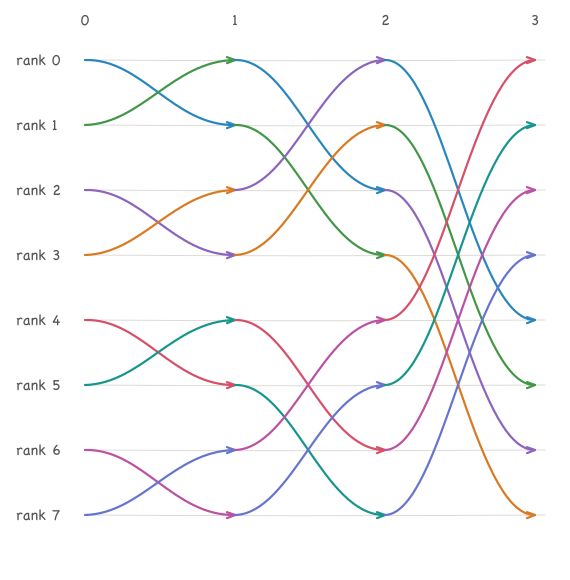

In [19]:
show_trace(trace)


In [20]:
check_tree_all_gather(tree_all_gather)


All checks passed.


### Same data, fewer exchanges

The four-rank pictures showed three exchanges for the ring and two for recursive
doubling. Let's use 64 workers to make that difference more visible, giving both
solutions the same pieces. Compare the messages with the bytes sent.


In [21]:
world_size = 64
values = [torch.full((16,), rank, dtype=torch.float32) for rank in range(world_size)]
expected = [torch.cat(values)] * world_size
summaries = {}
for name, collective in (
    ("Ring all-gather", ring_all_gather),
    ("Tree all-gather", tree_all_gather),
):
    run = flock.distribute(workers=world_size, seed=0, trace=True)(collective)
    results, trace = run(flock.per_rank([x.clone() for x in values]))
    check(results, expected)
    summaries[name] = trace.summary()

show_bars(
    "Messages sent by the busiest rank",
    {name: max(summary.messages_sent) for name, summary in summaries.items()},
    "messages",
)
show_bars(
    "Bytes sent across all ranks",
    {name: summary.total_bytes / 1024 for name, summary in summaries.items()},
    "KiB",
)


Messages sent by the busiest rank
Ring all-gather ████████████████████████████████████████████████ 63 messages
Tree all-gather █████                                            6 messages

Bytes sent across all ranks
Ring all-gather ████████████████████████████████████████████████ 252 KiB
Tree all-gather ████████████████████████████████████████████████ 252 KiB



The ring sends **63 messages per rank**; recursive doubling sends **6**. Both move the
same total amount of data. The difference is how much each message carries:

```text
Ring:  1 + 1 + 1 + ... + 1       = 63 original pieces
Tree:  1 + 2 + 4 + 8 + 16 + 32   = 63 original pieces
```

Each exchange supplies the data needed for the next one. These dependent stages are
**communication rounds**: `P - 1` for the ring, `log2(P)` for recursive doubling.
Here that means 63 rounds versus 6. These counts come from the exchange pattern;
the bars above count messages recorded by the tracer.

This is the latency side of our cost model: fewer successive exchanges mean paying
the startup cost fewer times along the way. The bytes have not disappeared; we have
changed how many messages carry them. With small pieces, that can make a substantial
difference.
